# Two-species full eco-evolutionary model with density-independent infanticide

## Models
For each species $i=1,2$, let $j \neq i$. Define

$$
M_i=M_{N,i}+M_{I,i},\qquad q_{N,i}=\frac{M_{N,i}}{M_i},\qquad q_{I,i}=\frac{M_{I,i}}{M_i},\qquad h_i=\gamma_i q_{I,i}
$$

When $M_i>0$, the flows from free females into the early parental-care stage are $\alpha_i q_{N,i}F_{f,i}$ and $\alpha_i q_{I,i}F_{f,i}$. When $M_i=0$, both flows into parental care are set to zero.

$$
\begin{aligned}
\dot{F}_{f,i} &= -\alpha_i (q_{N,i}+q_{I,i}) F_{f,i} + \left(1+b_{N,i}\right) \beta_i C_{2,N,i} + \left(1+b_{I,i}\right) \beta_i C_{2,I,i} - d_i \left(N_i + \rho_{ij} N_j\right) F_{f,i} \\
\dot{C}_{1,N,i} &= \alpha_i \frac{M_{N,i}}{M_{N,i}+M_{I,i}} F_{f,i} - \left(\beta_i + d_i \left(N_i + \rho_{ij} N_j\right) + h_i\right) C_{1,N,i} \\
\dot{C}_{2,N,i} &= \beta_i C_{1,N,i} - \left(\beta_i + d_i \left(N_i + \rho_{ij} N_j\right) + h_i\right) C_{2,N,i} \\
\dot{C}_{1,I,i} &= \alpha_i \frac{M_{I,i}}{M_{N,i}+M_{I,i}} F_{f,i} + h_i \left(C_{1,N,i} + C_{2,N,i} + C_{2,I,i}\right) - \left(\beta_i + d_i \left(N_i + \rho_{ij} N_j\right)\right) C_{1,I,i} \\
\dot{C}_{2,I,i} &= \beta_i C_{1,I,i} - \left(\beta_i + d_i \left(N_i + \rho_{ij} N_j\right) + h_i\right) C_{2,I,i} \\
\dot{M}_{N,i} &= b_{N,i} \beta_i C_{2,N,i} - d_i \left(N_i + \rho_{ij} N_j\right) M_{N,i} \\
\dot{M}_{I,i} &= b_{I,i} \beta_i C_{2,I,i} - d_i \left(N_i + \rho_{ij} N_j\right) M_{I,i}
\end{aligned}
$$

where

$$
\begin{aligned}
N_i &= F_{f,i} + C_{1,N,i} + C_{2,N,i} + C_{1,I,i} + C_{2,I,i} + M_{N,i} + M_{I,i} \\
b_{I,i} &= \left(1-s_i\right) b_{N,i} \\
p_i &= \frac{M_{I,i}}{M_{N,i} + M_{I,i}}
\end{aligned}
$$


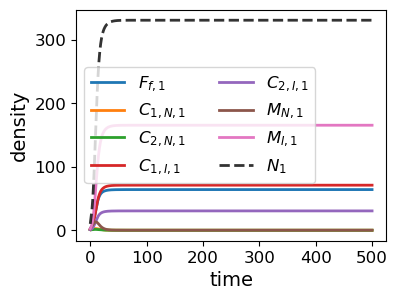

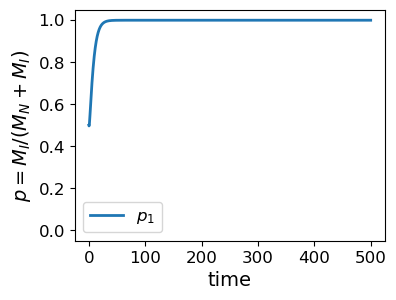

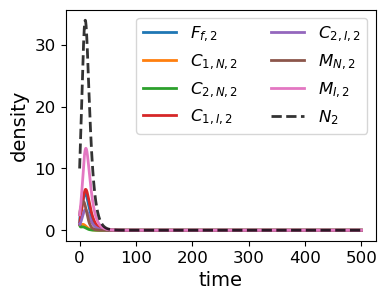

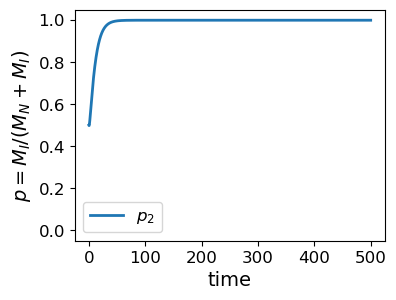

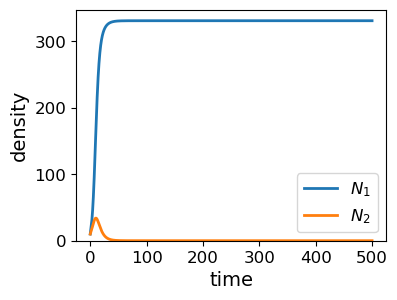

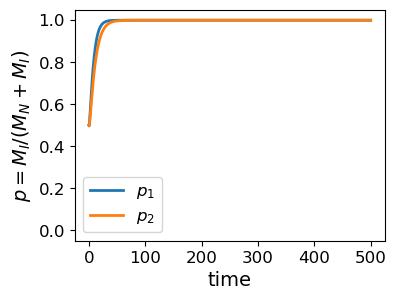

In [16]:
from collections import Counter
from functools import lru_cache

import numpy as np
from numpy.polynomial import Polynomial
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch
from scipy.integrate import solve_ivp
from scipy.ndimage import distance_transform_edt
from scipy.optimize import brentq
from tqdm.auto import tqdm

FIGURE_SIZE = (4, 3)
AXIS_LABEL_SIZE = 14
TICK_LABEL_SIZE = 12
DENSITY_TOL = 1e-7
STRATEGY_TOL = 1e-6
DISPLAY_END = 500.0
INITIAL_STATE = np.tile(np.array([1., 1., 1., 1., 1., 2.5, 2.5]), 2)


def strategy_label(p, tol=STRATEGY_TOL):
    if not np.isfinite(p):
        return 'undefined'
    return '0' if p <= tol else '1' if p >= 1 - tol else 'polymorphic'


def evolution_outcome(metrics, density_tol=DENSITY_TOL):
    present = [metrics[f'N{i}'] > density_tol for i in (1, 2)]
    if all(present):
        return f"sp1:{strategy_label(metrics['p1'])} | sp2:{strategy_label(metrics['p2'])}"
    if present[0]:
        return f"species2_excluded | sp1:{strategy_label(metrics['p1'])}"
    if present[1]:
        return f"species1_excluded | sp2:{strategy_label(metrics['p2'])}"
    return 'both_extinct'


def style_time_series(ax, ylabel):
    ax.set_xlabel('time', fontsize=AXIS_LABEL_SIZE)
    ax.set_ylabel(ylabel, fontsize=AXIS_LABEL_SIZE)
    ax.tick_params(axis='both', labelsize=TICK_LABEL_SIZE)


def plot_pair(time, series, symbol, ylabel, ylim, end=None):
    fig, ax = plt.subplots(figsize=FIGURE_SIZE)
    for i, values in enumerate(series, start=1):
        ax.plot(time, values, label=rf'${symbol}_{i}$', lw=2)
    ax.set_ylim(*ylim)
    if end is not None:
        ax.set_xlim(0, end)
    style_time_series(ax, ylabel)
    ax.legend(frameon=True, fontsize=TICK_LABEL_SIZE)
    return fig, ax


params = {
    'alpha1': 1.0,
    'beta1': 1.0,
    'gamma1': 1.00,
    'd1': 0.001,
    'b_N1': 2.0,
    's1': 0.1,

    'alpha2': 1.0,
    'beta2': 1.0,
    'gamma2': 1.00,
    'd2': 0.001,
    'b_N2': 1.0,
    's2': 0.1,

    'rho12': 1.0,
    'rho21': 1.0,
}


def male_type_frequencies(M_N, M_I, tol=0.0):
    male_total = M_N + M_I
    if male_total <= tol:
        return 0.0, 0.0
    return M_N / male_total, M_I / male_total


def two_species_ecoevo_rhs(time, y, params):
    (
        F_f1, C1_N1, C2_N1, C1_I1, C2_I1, M_N1, M_I1,
        F_f2, C1_N2, C2_N2, C1_I2, C2_I2, M_N2, M_I2,
    ) = y

    N1 = F_f1 + C1_N1 + C2_N1 + C1_I1 + C2_I1 + M_N1 + M_I1
    N2 = F_f2 + C1_N2 + C2_N2 + C1_I2 + C2_I2 + M_N2 + M_I2

    alpha1 = params['alpha1']
    beta1 = params['beta1']
    gamma1 = params['gamma1']
    d1 = params['d1']
    b_N1 = params['b_N1']
    s1 = params['s1']
    b_I1 = (1.0 - s1) * b_N1

    alpha2 = params['alpha2']
    beta2 = params['beta2']
    gamma2 = params['gamma2']
    d2 = params['d2']
    b_N2 = params['b_N2']
    s2 = params['s2']
    b_I2 = (1.0 - s2) * b_N2

    rho12 = params['rho12']
    rho21 = params['rho21']

    comp1 = d1 * (N1 + rho12 * N2)
    comp2 = d2 * (N2 + rho21 * N1)

    q_N1, q_I1 = male_type_frequencies(M_N1, M_I1)
    q_N2, q_I2 = male_type_frequencies(M_N2, M_I2)
    mating_N1 = alpha1 * q_N1 * F_f1
    mating_I1 = alpha1 * q_I1 * F_f1
    mating_N2 = alpha2 * q_N2 * F_f2
    mating_I2 = alpha2 * q_I2 * F_f2
    h1 = gamma1 * q_I1
    h2 = gamma2 * q_I2

    dF_f1 = -(mating_N1 + mating_I1) + (1.0 + b_N1) * beta1 * C2_N1 + (1.0 + b_I1) * beta1 * C2_I1 - comp1 * F_f1
    dC1_N1 = mating_N1 - (beta1 + comp1 + h1) * C1_N1
    dC2_N1 = beta1 * C1_N1 - (beta1 + comp1 + h1) * C2_N1
    dC1_I1 = mating_I1 + h1 * (C1_N1 + C2_N1 + C2_I1) - (beta1 + comp1) * C1_I1
    dC2_I1 = beta1 * C1_I1 - (beta1 + comp1 + h1) * C2_I1
    dM_N1 = b_N1 * beta1 * C2_N1 - comp1 * M_N1
    dM_I1 = b_I1 * beta1 * C2_I1 - comp1 * M_I1

    dF_f2 = -(mating_N2 + mating_I2) + (1.0 + b_N2) * beta2 * C2_N2 + (1.0 + b_I2) * beta2 * C2_I2 - comp2 * F_f2
    dC1_N2 = mating_N2 - (beta2 + comp2 + h2) * C1_N2
    dC2_N2 = beta2 * C1_N2 - (beta2 + comp2 + h2) * C2_N2
    dC1_I2 = mating_I2 + h2 * (C1_N2 + C2_N2 + C2_I2) - (beta2 + comp2) * C1_I2
    dC2_I2 = beta2 * C1_I2 - (beta2 + comp2 + h2) * C2_I2
    dM_N2 = b_N2 * beta2 * C2_N2 - comp2 * M_N2
    dM_I2 = b_I2 * beta2 * C2_I2 - comp2 * M_I2

    return np.array([
        dF_f1, dC1_N1, dC2_N1, dC1_I1, dC2_I1, dM_N1, dM_I1,
        dF_f2, dC1_N2, dC2_N2, dC1_I2, dC2_I2, dM_N2, dM_I2,
    ], dtype=float)

def integrate_nodens(t_span,initial,params,t_eval=None,rtol=1e-8,atol=1e-11):
    """Integrate the identical model using log densities and state fractions.

    This keeps frequency denominators well scaled when one species becomes
    very rare. Returned y has the original 14-state ordering; fractions and
    log_densities are retained to plot the rare-species frequency without a
    density cutoff or division of underflowed absolute densities.
    """
    initial=np.asarray(initial,dtype=float).reshape(2,7)
    if np.min(initial)<0 or np.any(initial.sum(axis=1)<=0):
        raise ValueError('Each initial species must have positive total density.')
    initial_densities=initial.sum(axis=1)
    initial_fractions=initial/initial_densities[:,None]
    transformed_initial=np.r_[initial_fractions.ravel(),np.log(initial_densities)]
    demographic_params=dict(params,d1=0.,d2=0.)

    def transformed_rhs(time,state):
        z=np.maximum(state[:14].reshape(2,7),0.)
        z=z/z.sum(axis=1)[:,None]
        demographic=two_species_ecoevo_rhs(time,z.ravel(),demographic_params).reshape(2,7)
        intrinsic=demographic.sum(axis=1)
        shape_derivative=demographic-intrinsic[:,None]*z
        with np.errstate(under='ignore'):
            densities=np.exp(np.minimum(state[14:],700.))
        mortality=np.array([
            params['d1']*(densities[0]+params['rho12']*densities[1]),
            params['d2']*(densities[1]+params['rho21']*densities[0]),
        ])
        return np.r_[shape_derivative.ravel(),intrinsic-mortality]

    result=solve_ivp(transformed_rhs,t_span,transformed_initial,method='LSODA',
                     t_eval=t_eval,rtol=rtol,atol=atol)
    z=np.maximum(result.y[:14].reshape(2,7,-1),0.)
    z=z/z.sum(axis=1)[:,None,:]
    logs=result.y[14:].copy()
    with np.errstate(under='ignore'):
        densities=np.exp(np.minimum(logs,700.))
    result['fractions']=z.reshape(14,-1)
    result['log_densities']=logs
    result.y=(z*densities[:,None,:]).reshape(14,-1)
    return result


# N1=N2=10, p1=p2=0.5; equal female states and equal sex totals.
y0 = INITIAL_STATE.copy()

t_span = (0.0, 500.0)
t_eval = np.linspace(t_span[0], t_span[1], 2000)

sol = integrate_nodens(t_span,y0,params,t_eval=t_eval,rtol=1e-8,atol=1e-10)

if not sol.success:
    raise RuntimeError(sol.message)

(
    F_f1, C1_N1, C2_N1, C1_I1, C2_I1, M_N1, M_I1,
    F_f2, C1_N2, C2_N2, C1_I2, C2_I2, M_N2, M_I2,
) = sol.y

N1 = F_f1 + C1_N1 + C2_N1 + C1_I1 + C2_I1 + M_N1 + M_I1
N2 = F_f2 + C1_N2 + C2_N2 + C1_I2 + C2_I2 + M_N2 + M_I2
p1 = sol.fractions[6] / (sol.fractions[5] + sol.fractions[6])
p2 = sol.fractions[13] / (sol.fractions[12] + sol.fractions[13])

def plot_species(time, species_idx, F_f, C1_N, C2_N, C1_I, C2_I, M_N, M_I, N, p):
    fig, ax = plt.subplots(figsize=FIGURE_SIZE)
    ax.plot(time, F_f, label=rf'$F_{{f,{species_idx}}}$', lw=2)
    ax.plot(time, C1_N, label=rf'$C_{{1,N,{species_idx}}}$', lw=2)
    ax.plot(time, C2_N, label=rf'$C_{{2,N,{species_idx}}}$', lw=2)
    ax.plot(time, C1_I, label=rf'$C_{{1,I,{species_idx}}}$', lw=2)
    ax.plot(time, C2_I, label=rf'$C_{{2,I,{species_idx}}}$', lw=2)
    ax.plot(time, M_N, label=rf'$M_{{N,{species_idx}}}$', lw=2)
    ax.plot(time, M_I, label=rf'$M_{{I,{species_idx}}}$', lw=2)
    ax.plot(time, N, label=rf'$N_{species_idx}$', lw=2, ls='--', color='black', alpha=0.8)
    style_time_series(ax, 'density')
    ax.legend(ncol=2, frameon=True, fontsize=TICK_LABEL_SIZE)

    fig, ax = plt.subplots(figsize=FIGURE_SIZE)
    ax.plot(time, p, lw=2)
    ax.set_ylim(-0.05, 1.05)
    style_time_series(ax, r'$p = M_I / (M_N + M_I)$')
    ax.lines[0].set_label(rf'$p_{species_idx}$')
    ax.legend(frameon=True, fontsize=TICK_LABEL_SIZE)

plot_species(sol.t, 1, F_f1, C1_N1, C2_N1, C1_I1, C2_I1, M_N1, M_I1, N1, p1)
plot_species(sol.t, 2, F_f2, C1_N2, C2_N2, C1_I2, C2_I2, M_N2, M_I2, N2, p2)

plot_pair(sol.t, [N1, N2], 'N', 'density', (-0.05, None))
plot_pair(sol.t, [p1, p2], 'p', r'$p = M_I / (M_N + M_I)$', (-0.05, 1.05))
plt.show()


### Setup

In [17]:
def _species_state(y, offset):
    return np.asarray(y[offset : offset + 7], dtype=float)


def male_frequency_derivatives(M_N, M_I, tol=0.0):
    male_total = M_N + M_I
    if male_total <= tol:
        return 0.0, 0.0, 0.0, 0.0, 0.0, 0.0
    male_total_sq = male_total * male_total
    q_N = M_N / male_total
    q_I = M_I / male_total
    dqN_dMN = M_I / male_total_sq
    dqN_dMI = -M_N / male_total_sq
    dqI_dMN = -M_I / male_total_sq
    dqI_dMI = M_N / male_total_sq
    return q_N, q_I, dqN_dMN, dqN_dMI, dqI_dMN, dqI_dMI


def _fill_species_jacobian(
    J,
    y,
    offset,
    other_offset,
    alpha,
    beta,
    gamma,
    d,
    b_N,
    s,
    rho,
):
    F, C1_N, C2_N, C1_I, C2_I, M_N, M_I = _species_state(y, offset)
    N_self = F + C1_N + C2_N + C1_I + C2_I + M_N + M_I
    N_other = float(np.sum(_species_state(y, other_offset)))
    comp = d * (N_self + rho * N_other)
    b_I = (1.0 - s) * b_N
    q_N, q_I, dqN_dMN, dqN_dMI, dqI_dMN, dqI_dMI = male_frequency_derivatives(M_N, M_I)
    h = gamma * q_I
    dh_dMN = gamma * dqI_dMN
    dh_dMI = gamma * dqI_dMI
    reset_source = C1_N + C2_N + C2_I

    local = slice(offset, offset + 7)
    other = slice(other_offset, other_offset + 7)
    row_values = np.array([F, C1_N, C2_N, C1_I, C2_I, M_N, M_I], dtype=float)
    J[offset : offset + 7, other] = -d * rho * row_values[:, None]

    J[offset + 0, local] = [
        -alpha * (q_N + q_I) - comp - d * F,
        -d * F,
        (1.0 + b_N) * beta - d * F,
        -d * F,
        (1.0 + b_I) * beta - d * F,
        -d * F,
        -d * F,
    ]
    J[offset + 1, local] = [
        alpha * q_N - d * C1_N,
        -beta - comp - h - d * C1_N,
        -d * C1_N,
        -d * C1_N,
        -d * C1_N,
        alpha * F * dqN_dMN - d * C1_N - dh_dMN * C1_N,
        alpha * F * dqN_dMI - d * C1_N - dh_dMI * C1_N,
    ]
    J[offset + 2, local] = [
        -d * C2_N,
        beta - d * C2_N,
        -beta - comp - h - d * C2_N,
        -d * C2_N,
        -d * C2_N,
        -d * C2_N - dh_dMN * C2_N,
        -d * C2_N - dh_dMI * C2_N,
    ]
    J[offset + 3, local] = [
        alpha * q_I - d * C1_I,
        h - d * C1_I,
        h - d * C1_I,
        -beta - comp - d * C1_I,
        h - d * C1_I,
        alpha * F * dqI_dMN + dh_dMN * reset_source - d * C1_I,
        alpha * F * dqI_dMI + dh_dMI * reset_source - d * C1_I,
    ]
    J[offset + 4, local] = [
        -d * C2_I,
        -d * C2_I,
        -d * C2_I,
        beta - d * C2_I,
        -beta - comp - h - d * C2_I,
        -d * C2_I - dh_dMN * C2_I,
        -d * C2_I - dh_dMI * C2_I,
    ]
    J[offset + 5, local] = [
        -d * M_N,
        -d * M_N,
        b_N * beta - d * M_N,
        -d * M_N,
        -d * M_N,
        -comp - d * M_N,
        -d * M_N,
    ]
    J[offset + 6, local] = [
        -d * M_I,
        -d * M_I,
        -d * M_I,
        -d * M_I,
        b_I * beta - d * M_I,
        -d * M_I,
        -comp - d * M_I,
    ]


def two_species_analytic_jacobian(y, params):
    """Analytic Jacobian of the full 14-dimensional two-species ODE."""
    y = np.asarray(y, dtype=float)
    J = np.zeros((14, 14), dtype=float)
    _fill_species_jacobian(
        J,
        y,
        offset=0,
        other_offset=7,
        alpha=params["alpha1"],
        beta=params["beta1"],
        gamma=params["gamma1"],
        d=params["d1"],
        b_N=params["b_N1"],
        s=params["s1"],
        rho=params["rho12"],
    )
    _fill_species_jacobian(
        J,
        y,
        offset=7,
        other_offset=0,
        alpha=params["alpha2"],
        beta=params["beta2"],
        gamma=params["gamma2"],
        d=params["d2"],
        b_N=params["b_N2"],
        s=params["s2"],
        rho=params["rho21"],
    )
    return J


def classify_stability_margin(stability_margin, eigen_tol=1e-8):
    if stability_margin < -eigen_tol:
        return "stable"
    if stability_margin > eigen_tol:
        return "unstable"
    return "neutral"


def _species_family(y_species, tol=DENSITY_TOL):
    F, C1_N, C2_N, C1_I, C2_I, M_N, M_I = np.asarray(y_species, dtype=float)
    N = float(F + C1_N + C2_N + C1_I + C2_I + M_N + M_I)
    if N <= tol:
        return "extinct"
    if M_I <= tol and M_N > tol:
        return "p0"
    if M_N <= tol and M_I > tol:
        return "p1"
    if M_N + M_I <= tol:
        return "no_males"
    return "interior"


def equilibrium_family_2sp(y, tol=DENSITY_TOL):
    y = np.asarray(y, dtype=float)
    return f"sp1:{_species_family(y[:7], tol)}|sp2:{_species_family(y[7:], tol)}"


def two_species_equilibrium_metrics(y):
    y = np.asarray(y, dtype=float)
    y1 = y[:7]
    y2 = y[7:]
    N1 = float(np.sum(y1))
    N2 = float(np.sum(y2))
    male1 = y1[5] + y1[6]
    male2 = y2[5] + y2[6]
    p1 = float(y1[6] / male1) if male1 > 1e-12 else np.nan
    p2 = float(y2[6] / male2) if male2 > 1e-12 else np.nan
    return {"N1": N1, "N2": N2, "p1": p1, "p2": p2}


def nodens_noninfanticide_growth(alpha,beta,b_N):
    """Perron growth rate of the non-infanticidal demographic subsystem."""
    if min(alpha,beta,b_N)<=0:
        raise ValueError('alpha, beta and b_N must be positive.')
    if alpha==beta:
        return alpha*np.expm1(np.log1p(b_N)/3.)
    equation=lambda c:(alpha+c)*(beta+c)**2-alpha*(1+b_N)*beta**2
    upper=max(alpha,beta)
    while equation(upper)<=0:upper*=2
    return float(brentq(equation,0.,upper,xtol=1e-14))


@lru_cache(maxsize=4096)
def _nodens_intrinsic_profiles(alpha,beta,gamma,b_N,s):
    """All positive demographic eigenprofiles; total density normalized to one.

    The mortality-free RHS is homogeneous of degree one. At a stationary
    composition it satisfies f(z)=c*z. Uniform competition mortality does not
    change composition, so these profiles are independent of d and rho.

    For interior p, let q=1-s, N(c)=gamma*q*(2*beta+c)-s*(beta+c)^2,
    Q(c)=gamma*(s*c-gamma*q), and T(c)=(beta+c)*Q+gamma*N.
    Then p=N/Q and q*(alpha+c)*T^2-
    alpha*beta^2*(q*(1+b_N)*Q^2+s*N*Q)=0, a cubic polynomial.
    Every candidate is checked in the original seven demographic equations.
    """
    if min(alpha,beta,b_N)<=0 or gamma<0 or not 0<=s<=1:
        raise ValueError('Positive demographics, gamma>=0 and 0<=s<=1 required.')
    c_N=nodens_noninfanticide_growth(alpha,beta,b_N)
    candidates=[]
    C1=alpha/(beta+c_N);C2=beta*C1/(beta+c_N)
    local=np.array([1.,C1,C2,0.,0.,b_N*beta*C2/c_N,0.])
    candidates.append((c_N,0.,local))
    b_I=(1-s)*b_N
    if b_I>0:
        equation=lambda c:(alpha+c)*((beta+c)**2+gamma*c)-alpha*(1+b_I)*beta**2
        upper=max(alpha,beta,gamma,1.)
        while equation(upper)<=0:upper*=2
        c_I=float(brentq(equation,0.,upper,xtol=1e-14))
        C1=(beta+c_I+gamma)/beta
        F=((beta+c_I)*C1-gamma)/alpha
        local=np.array([F,0.,0.,C1,1.,0.,b_I*beta/c_I])
        candidates.append((c_I,1.,local))
    if gamma>0 and 0<s<1:
        x=Polynomial([0.,1.]);q=1-s
        numerator=gamma*q*(2*beta+x)-s*(beta+x)**2
        denominator=gamma*(s*x-gamma*q)
        # Algebraically simplified form avoids cancelling quadratic terms.
        T=gamma*beta*(gamma*q-s*(beta+x))
        polynomial=q*(alpha+x)*T**2-alpha*beta**2*(q*(1+b_N)*denominator**2+s*numerator*denominator)
        for root in polynomial.roots():
            if abs(root.imag)>1e-8:continue
            c=float(root.real)
            if not (0<c<=c_N*(1+1e-9)) or abs(denominator(c))<1e-12:continue
            p=float(numerator(c)/denominator(c))
            if not (1e-10<p<1-1e-10):continue
            h=gamma*p;M_N=1-p;M_I=p
            C2N=c*M_N/(b_N*beta);C2I=c*M_I/(b_I*beta)
            F=c*(beta+c+h)**2/(b_N*beta**2*alpha)
            local=np.array([F,(beta+c+h)*C2N/beta,C2N,(beta+c+h)*C2I/beta,C2I,M_N,M_I])
            candidates.append((c,p,local))
    profiles=[]
    for c,p,local in candidates:
        if np.min(local)<-1e-10:continue
        z=np.maximum(local,0.);z/=z.sum()
        F,C1N,C2N,C1I,C2I,MN,MI=z
        total=MN+MI;qn=MN/total;qi=MI/total;h=gamma*qi
        f=np.array([
            -alpha*F+(1+b_N)*beta*C2N+(1+b_I)*beta*C2I,
            alpha*qn*F-(beta+h)*C1N,
            beta*C1N-(beta+h)*C2N,
            alpha*qi*F+h*(C1N+C2N+C2I)-beta*C1I,
            beta*C1I-(beta+h)*C2I,
            b_N*beta*C2N,b_I*beta*C2I,
        ])
        error=float(np.max(abs(f-c*z)))
        if error>1e-8:
            raise RuntimeError(f'Demographic profile failed residual check: {error}')
        if any(abs(p-old['p'])<1e-9 and abs(c-old['growth'])<1e-9 for old in profiles):continue
        profiles.append({'growth':c,'p':p,'fraction':z,'profile_residual':error})
    return tuple(profiles)


def nodens_intrinsic_profiles(params,species_idx):
    return _nodens_intrinsic_profiles(*(float(params[f'{key}{species_idx}'])
        for key in ('alpha','beta','gamma','b_N','s')))


def nodens_full_stability(y,params,eigen_tol=1e-8,jacobian=None):
    """Full Jacobian for positive species; sharp invasion bound at extinction.

    Among all rare demographic compositions, the non-infanticidal profile
    attains the maximal intrinsic growth c_N: infanticide delays C2 maturation
    and b_I<=b_N. A positive reproductive-value weighting of the aggregate
    female stages bounds every other trajectory by this growth rate.
    Thus c_N-d_i*rho_ij*N_j<0 excludes all rare strategies, not just p=0.
    Conversely a pure-N rare population grows if this quantity is positive.
    This avoids differentiating male frequencies at an absent species.
    """
    y=np.asarray(y,dtype=float)
    densities=[float(y[:7].sum()),float(y[7:].sum())]
    present=[N>DENSITY_TOL for N in densities]
    J=two_species_analytic_jacobian(y,params) if jacobian is None else jacobian
    invasion={}
    if all(present):
        eigenvalues=np.linalg.eigvals(J)
        method='full nodens analytic Jacobian'
    else:
        active=[k for i in range(2) if present[i] for k in range(7*i,7*i+7)]
        resident=np.linalg.eigvals(J[np.ix_(active,active)]) if active else np.array([],dtype=complex)
        for i in range(2):
            if not present[i]:
                species=i+1
                intrinsic=nodens_noninfanticide_growth(params[f'alpha{species}'],params[f'beta{species}'],params[f'b_N{species}'])
                competition=params['rho12' if i==0 else 'rho21']
                invasion[f'species{species}']=intrinsic-params[f'd{species}']*competition*densities[1-i]
        eigenvalues=np.r_[resident,list(invasion.values())]
        method='resident nodens Jacobian and maximal feasible rare-species growth'
    margin=float(eigenvalues.real.max())
    return {'eigvals':eigenvalues,'stability_margin':margin,
        'stability_class':classify_stability_margin(margin,eigen_tol),
        'invasion_margins':invasion,'stability_method':method}


def nodens_equilibrium_record(y,params,eigen_tol=1e-8):
    y=np.asarray(y,dtype=float)
    if not np.all(np.isfinite(y)) or np.min(y)<0:raise ValueError('Nonphysical equilibrium.')
    residual=float(np.max(abs(two_species_ecoevo_rhs(0.,y,params))))
    if residual>1e-7:raise RuntimeError(f'Constructed equilibrium failed ODE check: {residual}')
    jacobian=two_species_analytic_jacobian(y,params)
    return {'y_star':y,'residual_norm':residual,
        'jacobian':jacobian,
        'family':equilibrium_family_2sp(y,tol=DENSITY_TOL),
        **two_species_equilibrium_metrics(y),**nodens_full_stability(y,params,eigen_tol,jacobian=jacobian)}


def nodens_enumerate_equilibria(params):
    """Enumerate pure and mixed profile pairs plus species-exclusion states."""
    if min(params['d1'],params['d2'])<=0 or min(params['rho12'],params['rho21'])<0:
        raise ValueError('Positive density mortality and nonnegative competition required.')
    profiles={i:nodens_intrinsic_profiles(params,i) for i in (1,2)}
    states=[np.zeros(14)]
    for i in (1,2):
        for profile in profiles[i]:
            local=profile['fraction']*profile['growth']/params[f'd{i}']
            states.append(np.r_[local,np.zeros(7)] if i==1 else np.r_[np.zeros(7),local])
    u,v=params['rho12'],params['rho21'];determinant=1-u*v
    for profile1 in profiles[1]:
        for profile2 in profiles[2]:
            K1=profile1['growth']/params['d1'];K2=profile2['growth']/params['d2']
            if abs(determinant)<1e-12:
                if not np.isclose(K1,u*K2,rtol=1e-12,atol=1e-10):continue
                # Representative of a continuum; its radial zero eigenvalue
                # prevents classification as asymptotically stable coexistence.
                N1,N2=K1/2,K2/2
            else:
                N1=(K1-u*K2)/determinant;N2=(K2-v*K1)/determinant
            if min(N1,N2)<=DENSITY_TOL:continue
            states.append(np.r_[profile1['fraction']*N1,profile2['fraction']*N2])
    equilibria=[nodens_equilibrium_record(y,params) for y in states]
    equilibria.sort(key=lambda e:(e['stability_class']!='stable',e['family'],e['N1']+e['N2']))
    return equilibria


### Full-model scan on the $(s,\rho)$ plane


In [18]:
def scan_s_rho_plane(base_params, s_values, rho_values):
    grid = []
    for s in tqdm(s_values, desc='Scanning (s, rho)', unit='row'):
        row = []
        for rho in rho_values:
            point_params = dict(base_params, s1=float(s), s2=float(s),
                                rho12=float(rho), rho21=float(rho))
            row.append(nodens_enumerate_equilibria(point_params))
        grid.append(row)
    return dict(s_values=np.asarray(s_values), rho_values=np.asarray(rho_values),
                equilibria_grid=grid, params=dict(base_params), model='nodens_gamma_p',
                equilibrium_method='all pure and cubic mixed demographic profiles, exact density equations',
                stability_method='positive-species Jacobian plus maximal feasible rare-species growth at boundaries')


s_values_2d = np.linspace(0.0, 1.0, 101)
rho_values_2d = np.linspace(0.0, 1.0, 101)
full_scan = scan_s_rho_plane(params, s_values_2d, rho_values_2d)
print('Computed all equilibrium candidates.')


Scanning (s, rho):   0%|          | 0/101 [00:00<?, ?row/s]

Computed all equilibrium candidates.


### All combinations of locally asymptotically stable equilibria

Extract all locally asymptotically stable equilibria from the computed equilibrium candidates and classify them by their ecological types and counts, together with the combinations of strategy states across the stable equilibria.


Stable ecological equilibrium sets: {'coexistence (1)': 5075, 'no locally stable equilibrium': 1915, 'species 1 only (1)': 2462, 'coexistence (2)': 181, 'coexistence (4)': 195, 'coexistence (3)': 345, 'coexistence (1) + species 1 only (1)': 28}


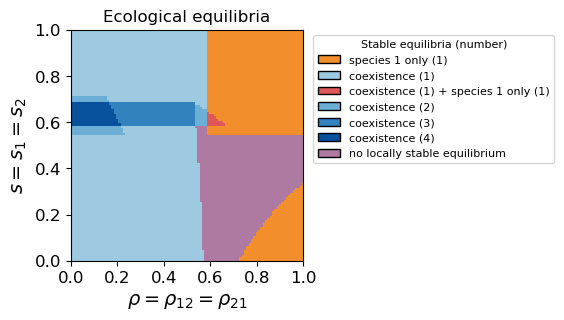

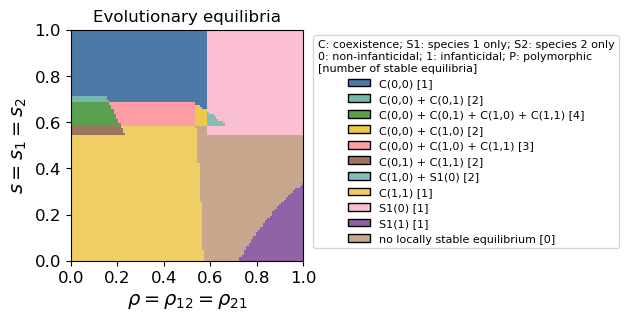

In [19]:
def stable_equilibrium_classification(scan):
    """Classify the complete stable-equilibrium set, without choosing a winner."""
    shape=(len(scan['s_values']),len(scan['rho_values']))
    ecology=np.empty(shape,dtype=object)
    evolution=np.empty(shape,dtype=object)
    counts=np.zeros(shape,dtype=int)
    type_counts={name:np.zeros(shape,dtype=int) for name in ('C','S1','S2','O')}
    ecology_names={};evolution_names={}
    for i,j in np.ndindex(shape):
        stable=[eq for eq in scan['equilibria_grid'][i][j]
                if eq['stability_class']=='stable']
        ecological=Counter();evolutionary=Counter()
        for eq in stable:
            present1=eq['N1']>DENSITY_TOL;present2=eq['N2']>DENSITY_TOL
            kind='C' if present1 and present2 else 'S1' if present1 else 'S2' if present2 else 'O'
            ecological[kind]+=1
            if kind=='C':
                state=f"C({strategy_label(eq['p1'])},{strategy_label(eq['p2'])})"
            elif kind=='S1':state=f"S1({strategy_label(eq['p1'])})"
            elif kind=='S2':state=f"S2({strategy_label(eq['p2'])})"
            else:state='O'
            evolutionary[state]+=1
        counts[i,j]=len(stable)
        for name in type_counts:type_counts[name][i,j]=ecological[name]
        key='|'.join(f'{name}:{ecological[name]}' for name in type_counts)
        evo_key='|'.join(f'{name}:{count}' for name,count in sorted(evolutionary.items())) or 'none'
        ecology[i,j]=key;evolution[i,j]=evo_key
        pretty={'C':'coexistence','S1':'species 1 only','S2':'species 2 only','O':'both extinct'}
        ecology_names[key]=' + '.join(f'{pretty[name]} ({ecological[name]})'
            for name in type_counts if ecological[name]) or 'no locally stable equilibrium'
        evolution_names[evo_key]=' + '.join(
            (f'{count} × ' if count>1 else '')+name.replace('polymorphic','P')
            for name,count in sorted(evolutionary.items()))+f' [{len(stable)}]' if stable else 'no locally stable equilibrium [0]'
    assert np.array_equal(counts,sum(type_counts.values()))
    return dict(ecology_grid=ecology,evolution_grid=evolution,stable_counts=counts,
        type_counts=type_counts,ecology_names=ecology_names,evolution_names=evolution_names)


def stable_equilibrium_palettes(classifications):
    ecological_keys=set();evolutionary_keys=set()
    for classification in classifications:
        ecological_keys.update(classification['ecology_names'])
        evolutionary_keys.update(classification['evolution_names'])
    def signature(key):return tuple(int(part.split(':')[1]) for part in key.split('|'))
    ecology_labels=sorted(ecological_keys,key=lambda key:(sum(signature(key))==0,signature(key)))
    ecology_colors={}
    # Blue tones distinguish one through four coexistence equilibria.
    blues={1:'#9ecae1',2:'#6baed6',3:'#3182bd',4:'#08519c'}
    fallback=iter(['#59a14f','#edc949','#9c755f','#ff9da7','#76b7b2','#b6992d'])
    for key in ecology_labels:
        c,s1,s2,origin=signature(key)
        if c and not(s1 or s2 or origin):color=blues[c] if c in blues else next(fallback)
        elif c and s1 and not(s2 or origin):color='#e15759' if (c,s1)==(1,1) else next(fallback)
        elif s1 and not(c or s2 or origin):color='#f28e2b' if s1==1 else next(fallback)
        elif sum(signature(key))==0:color='#af7aa1'
        else:color=next(fallback)
        ecology_colors[key]=color
    established = {
        'C(0,0):1': '#4e79a7',
        'C(0,0):1|C(0,1):1': '#76b7b2',
        'C(0,0):1|C(0,1):1|C(1,0):1|C(1,1):1': '#59a14f',
        'C(0,0):1|C(1,0):1': '#edc949',
        'C(0,0):1|C(1,0):1|C(1,1):1': '#ff9da7',
        'C(0,1):1|C(1,1):1': '#9c755f',
        'C(1,0):1': '#b6992d',
        'C(1,0):1|S1(0):1': '#86bcb6',
        'C(1,1):1': '#f1ce63',
        'C(1,1):1|S1(0):1': '#e19d9a',
        'S1(0):1': '#fabfd2', 'S1(1):1': '#8f63a6', 'none': '#c7a78d',
    }
    extra_colors=iter(['#2f4b7c','#003f5c','#bc5090','#58508d'])
    evolution_labels=sorted(evolutionary_keys,key=lambda key:(key=='none',key))
    evolution_colors={key:established[key] if key in established else next(extra_colors)
                      for key in evolution_labels}
    assert len(set(ecology_colors.values()))==len(ecology_colors)
    assert not set(ecology_colors.values()) & set(evolution_colors.values())
    return ecology_labels,ecology_colors,evolution_labels,evolution_colors


def draw_stable_equilibrium_plane(grid,x,y,labels,colors,names,xlabel,ylabel,title,legend_title):
    labels=[label for label in labels if np.any(grid==label)]
    codes=np.zeros(grid.shape,dtype=int)
    for number,label in enumerate(labels):codes[grid==label]=number
    cmap=ListedColormap([colors[label] for label in labels])
    norm=BoundaryNorm(np.arange(-.5,len(labels)+.5),len(labels))
    def edges(values):
        values=np.asarray(values)
        return np.r_[values[0]-(values[1]-values[0])/2,
                     (values[:-1]+values[1:])/2,values[-1]+(values[-1]-values[-2])/2]
    fig,ax=plt.subplots(figsize=(3.,3.))
    ax.pcolormesh(edges(x),edges(y),codes,cmap=cmap,norm=norm,shading='flat',
                  edgecolors='none',linewidth=0,antialiased=False,rasterized=True)
    ax.grid(False);ax.set_xlim(x[0],x[-1]);ax.set_ylim(y[0],y[-1])
    ax.set_xlabel(xlabel,fontsize=AXIS_LABEL_SIZE);ax.set_ylabel(ylabel,fontsize=AXIS_LABEL_SIZE)
    ax.set_xticks(np.arange(0,1.01,.2));ax.set_yticks(np.arange(0,1.01,.2))
    ax.tick_params(labelsize=TICK_LABEL_SIZE);ax.set_title(title)
    ax.legend(handles=[Patch(facecolor=colors[label],edgecolor='black',label=names[label]) for label in labels],
              loc='upper left',bbox_to_anchor=(1.02,1),fontsize=8,title=legend_title,title_fontsize=8)
    return fig,ax


def plot_stable_classes(classification,x,y,xlabel,ylabel,prefix,palettes):
    stable_ecology_labels,stable_ecology_colors,stable_evolution_labels,stable_evolution_colors=palettes
    ecological=draw_stable_equilibrium_plane(
        classification['ecology_grid'],x,y,stable_ecology_labels,stable_ecology_colors,
        classification['ecology_names'],xlabel,ylabel,prefix+'Ecological equilibria',
        'Stable equilibria (number)')
    evolutionary=draw_stable_equilibrium_plane(
        classification['evolution_grid'],x,y,stable_evolution_labels,stable_evolution_colors,
        classification['evolution_names'],xlabel,ylabel,prefix+'Evolutionary equilibria',
        'C: coexistence; S1: species 1 only; S2: species 2 only\n0: non-infanticidal; 1: infanticidal; P: polymorphic\n[number of stable equilibria]')
    return ecological,evolutionary

common_stable_classes = stable_equilibrium_classification(full_scan)
stable_palettes = stable_equilibrium_palettes([common_stable_classes])
print('Stable ecological equilibrium sets:', {
    common_stable_classes['ecology_names'][key]: count
    for key, count in Counter(common_stable_classes['ecology_grid'].ravel()).items()})
plot_stable_classes(common_stable_classes, full_scan['rho_values'], full_scan['s_values'],
    r'$\rho=\rho_{12}=\rho_{21}$', r'$s=s_1=s_2$', '',
    stable_palettes)
plt.show()


### Eco-evolutionary dynamics at representative points in each region

Select a representative point for each combination of stable equilibria, using the same classification as in the evolutionary phase diagram above.
If a class spans multiple disconnected regions, select one point for the entire class rather than one for each connected region.
For each species, the initial condition is $[F_f,C_{1,N},C_{2,N},C_{1,I},C_{2,I},M_N,M_I]=[1,1,1,1,1,2.5,2.5]$.
The displayed time range is $0\le t\le500$, and each figure measures 4 by 3 inches.
Retain the specified point $s=0.6,\rho=0.45$ as an additional point, separate from the automatically selected points.

region_01: C(0,0) [1]; s=0.8, rho=0.4; endpoint=sp1:0 | sp2:0; near_equilibrium=True; nearest_stability=stable; invasion={}


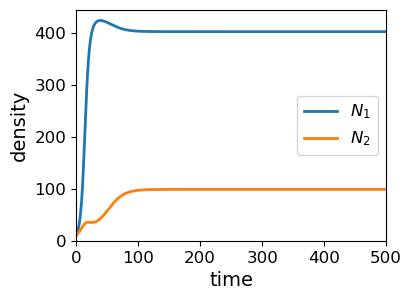

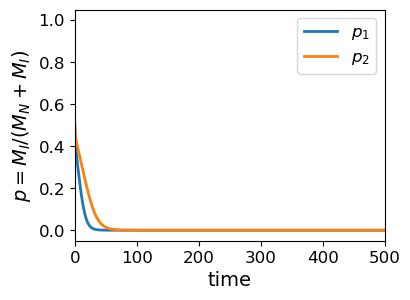

region_02: C(0,0) + C(0,1) [2]; s=0.7, rho=0.1; endpoint=sp1:0 | sp2:0; near_equilibrium=True; nearest_stability=stable; invasion={}


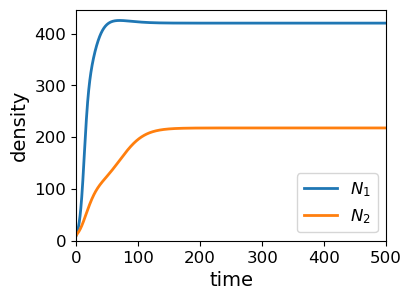

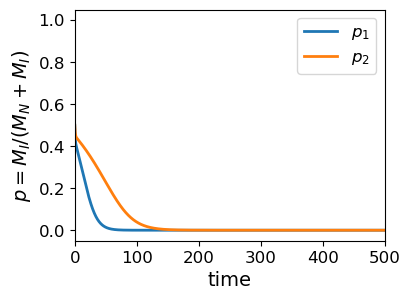

region_03: C(0,0) + C(0,1) + C(1,0) + C(1,1) [4]; s=0.6, rho=0.1; endpoint=sp1:1 | sp2:1; near_equilibrium=True; nearest_stability=stable; invasion={}


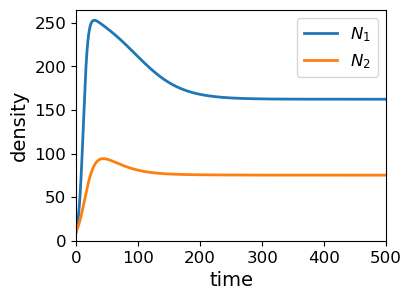

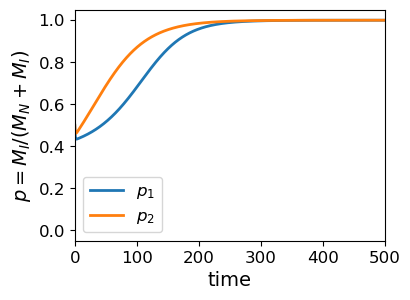

region_04: C(0,0) + C(1,0) [2]; s=0.6, rho=0.55; endpoint=sp1:1 | sp2:1; near_equilibrium=True; nearest_stability=unstable; invasion={'species2': np.float64(0.16647285594390243)}


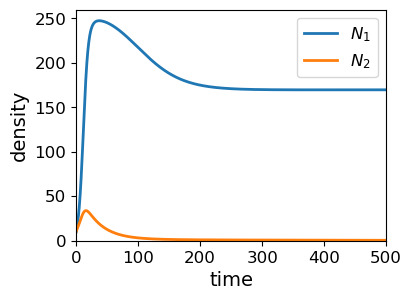

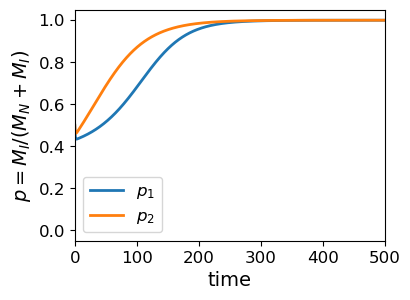

region_05: C(0,0) + C(1,0) + C(1,1) [3]; s=0.6, rho=0.5; endpoint=sp1:1 | sp2:1; near_equilibrium=True; nearest_stability=stable; invasion={}


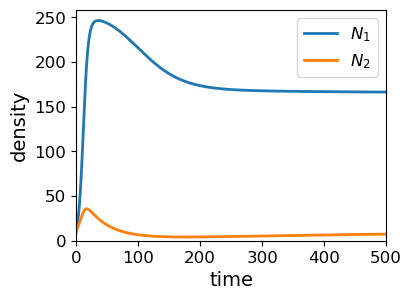

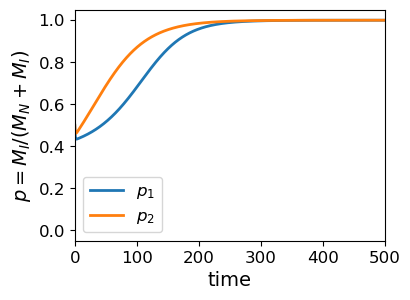

region_06: C(0,1) + C(1,1) [2]; s=0.56, rho=0.2; endpoint=sp1:1 | sp2:1; near_equilibrium=True; nearest_stability=stable; invasion={}


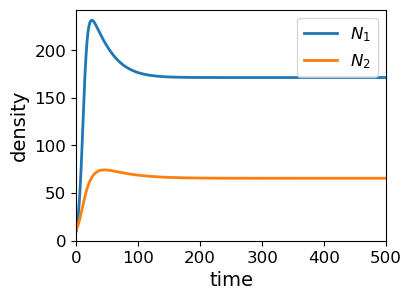

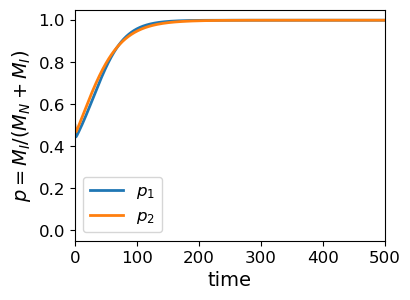

region_07: C(1,0) + S1(0) [2]; s=0.6, rho=0.6; endpoint=species2_excluded | sp1:1; near_equilibrium=True; nearest_stability=unstable; invasion={'species2': np.float64(0.1579775655847233)}


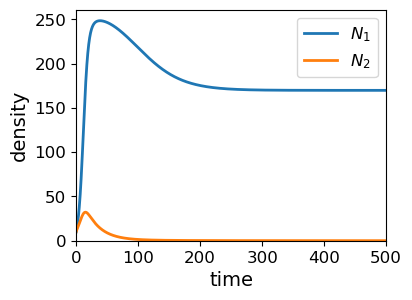

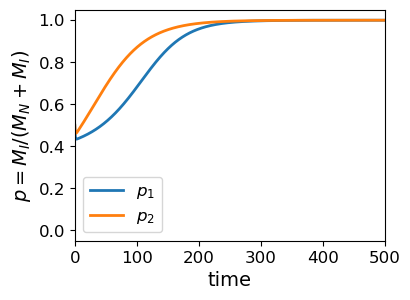

region_08: C(1,1) [1]; s=0.3, rho=0.3; endpoint=sp1:1 | sp2:1; near_equilibrium=True; nearest_stability=stable; invasion={}


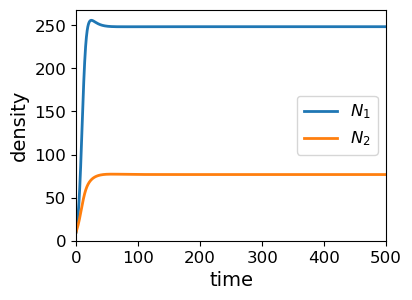

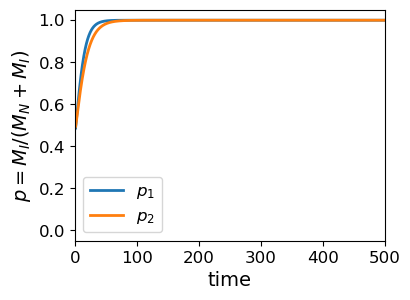

region_09: S1(0) [1]; s=0.8, rho=0.8; endpoint=species2_excluded | sp1:0; near_equilibrium=True; nearest_stability=stable; invasion={'species2': np.float64(-0.09387860635105377)}


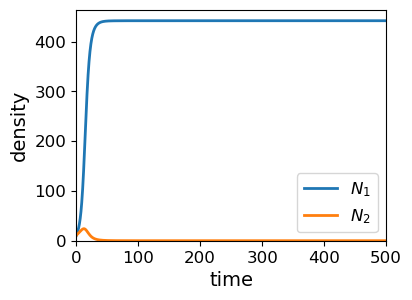

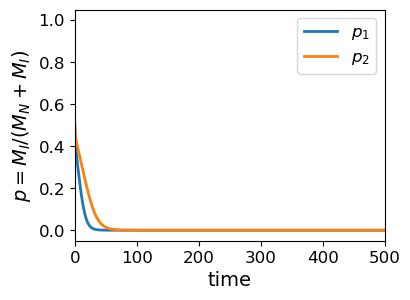

region_10: S1(1) [1]; s=0.1, rho=0.9; endpoint=species2_excluded | sp1:1; near_equilibrium=True; nearest_stability=stable; invasion={'species2': np.float64(-0.038171301230902566)}


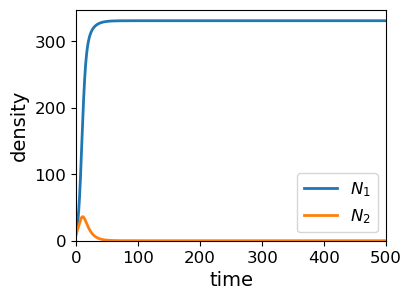

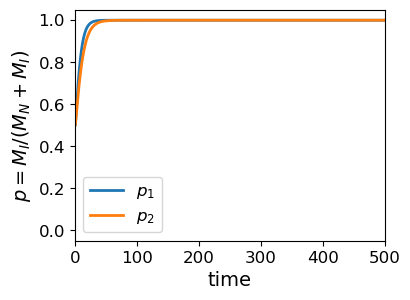

region_11: no locally stable equilibrium [0]; s=0.4, rho=0.7; endpoint=species2_excluded | sp1:1; near_equilibrium=True; nearest_stability=unstable; invasion={'species2': np.float64(0.09240660489208555)}


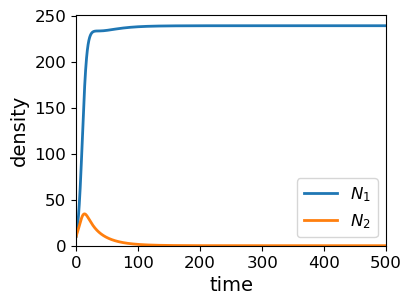

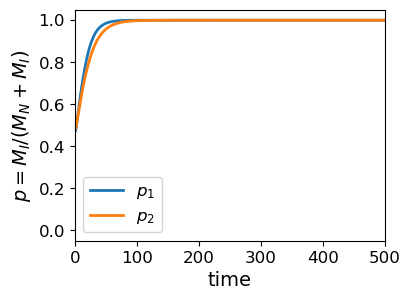

specified_s_0p6_rho_0p45: C(0,0) + C(1,0) + C(1,1) [3]; s=0.6, rho=0.45; endpoint=sp1:1 | sp2:1; near_equilibrium=True; nearest_stability=stable; invasion={}


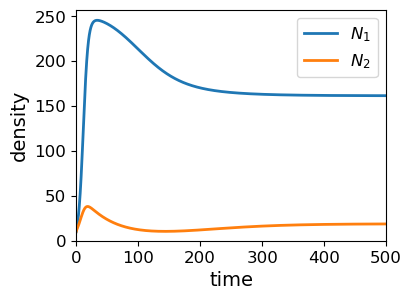

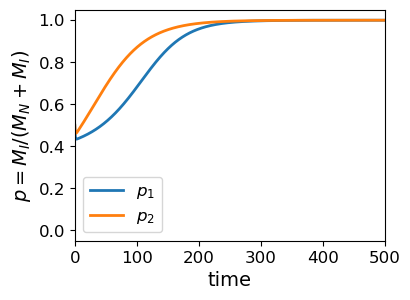

In [20]:
def decimal_complexity(value):
    if np.isclose(value, 0) or np.isclose(value, 1):
        return 0
    if np.isclose(value * 10, round(value * 10)):
        return 1
    if np.isclose(value * 20, round(value * 20)):
        return 2
    return 3


def representative_points(scan, classification):
    grid = classification['evolution_grid']
    points = []
    for label in sorted(set(grid.ravel()), key=lambda label: (label == 'none', label)):
        mask = grid == label
        distances = distance_transform_edt(np.pad(mask, 1))[1:-1, 1:-1]
        candidates = np.argwhere(mask & (distances >= min(2.0, float(distances.max()))))
        def score(point):
            i, j = point
            s, rho = scan['s_values'][i], scan['rho_values'][j]
            a, b = decimal_complexity(s), decimal_complexity(rho)
            return max(a, b), a + b, -distances[i, j], abs(s - .5) + abs(rho - .5), i, j
        i, j = min(candidates, key=score)
        points.append(dict(label=label, s=float(scan['s_values'][i]),
                           rho=float(scan['rho_values'][j]), selection='automatic'))
    return points


def trajectory_endpoint_metrics(trajectory):
    densities = trajectory.y[:, -1].reshape(2, 7).sum(axis=1)
    fractions = trajectory.fractions[:, -1].reshape(2, 7)
    male_totals = fractions[:, 5:7].sum(axis=1)
    frequencies = np.divide(fractions[:, 6], male_totals,
                            out=np.full(2, np.nan), where=male_totals > 0)
    metrics = dict(N1=float(densities[0]), N2=float(densities[1]),
                   p1=float(frequencies[0]), p2=float(frequencies[1]))
    return metrics


def integrate_representative(point_params, initial, display_end=DISPLAY_END, max_horizon=16000.):
    equilibria = nodens_enumerate_equilibria(point_params)
    horizon = max(1000., display_end)
    while True:
        times = np.unique(np.r_[np.linspace(0, display_end, 2000),
                                np.linspace(display_end, horizon, 2000)])
        trajectory = integrate_nodens((0., horizon), initial, point_params,
                                      t_eval=times, rtol=1e-8, atol=1e-11)
        if not trajectory.success:
            raise RuntimeError(trajectory.message)
        endpoint = trajectory.y[:, -1]
        residual = float(np.max(abs(two_species_ecoevo_rhs(horizon, endpoint, point_params)))) / max(1., float(np.max(endpoint)))
        nearest = min(equilibria, key=lambda eq: np.linalg.norm(eq['y_star'] - endpoint))
        distance = float(np.linalg.norm(nearest['y_star'] - endpoint) / max(1., np.linalg.norm(nearest['y_star'])))
        near_equilibrium = residual < 1e-7 and distance < 1e-7
        if near_equilibrium or horizon >= max_horizon:
            break
        horizon = min(2 * horizon, max_horizon)
    metrics = trajectory_endpoint_metrics(trajectory)
    return dict(trajectory=trajectory, endpoint_metrics=metrics,
                endpoint_label=evolution_outcome(metrics),
                endpoint_log_densities=trajectory.log_densities[:, -1].copy(),
                nearest_equilibrium=nearest,
                nearest_equilibrium_label=evolution_outcome(nearest),
                nearest_equilibrium_stability=nearest['stability_class'],
                invasion_margins=nearest['invasion_margins'],
                relative_rhs_norm=residual, equilibrium_distance=distance,
                near_equilibrium=near_equilibrium, integration_horizon=horizon,
                endpoint_density_tolerance=DENSITY_TOL)


points = representative_points(full_scan, common_stable_classes)
# Explicitly requested point; it never replaces a representative of another class.
requested_s, requested_rho = 0.6, 0.45
requested_params = dict(full_scan['params'], s1=requested_s, s2=requested_s,
                        rho12=requested_rho, rho21=requested_rho)
requested_classes = stable_equilibrium_classification(dict(
    s_values=[requested_s], rho_values=[requested_rho],
    equilibria_grid=[[nodens_enumerate_equilibria(requested_params)]]))
points.append(dict(label=requested_classes['evolution_grid'][0, 0],
                   s=requested_s, rho=requested_rho, selection='specified'))

region_dynamics_results = {}
for number, point in enumerate(points, start=1):
    slug = f'region_{number:02d}' if point['selection'] == 'automatic' else 'specified_s_0p6_rho_0p45'
    point_params = dict(full_scan['params'], s1=point['s'], s2=point['s'],
                        rho12=point['rho'], rho21=point['rho'])
    record = integrate_representative(point_params, INITIAL_STATE.copy())
    record.update(point=point, map_label=point['label'],
                  map_description=common_stable_classes['evolution_names'][point['label']],
                  params=point_params, y0=INITIAL_STATE.copy())
    trajectory = record['trajectory']
    populations = trajectory.y.reshape(2, 7, -1).sum(axis=1)
    fractions = trajectory.fractions.reshape(2, 7, -1)
    males = fractions[:, 5:7].sum(axis=1)
    frequencies = np.divide(fractions[:, 6], males, out=np.full_like(males, np.nan), where=males > 0)
    plot_pair(trajectory.t, populations, 'N', 'density', (-.05, None),
              end=DISPLAY_END)
    plot_pair(trajectory.t, frequencies, 'p', r'$p = M_I / (M_N + M_I)$', (-.05, 1.05),
              end=DISPLAY_END)
    region_dynamics_results[slug] = record
    print(f"{slug}: {record['map_description']}; s={point['s']:g}, rho={point['rho']:g}; "
          f"endpoint={record['endpoint_label']}; near_equilibrium={record['near_equilibrium']}; "
          f"nearest_stability={record['nearest_equilibrium_stability']}; "
          f"invasion={record['invasion_margins']}")
    plt.show()
